In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
import os

zip_path = "/content/drive/MyDrive/FYP - Wee Jia Sheen/sortsnap_dataset/sortsnap_dataset.zip"

print(os.path.exists(zip_path))
print(zip_path)

True
/content/drive/MyDrive/FYP - Wee Jia Sheen/sortsnap_dataset/sortsnap_dataset.zip


In [10]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/FYP - Wee Jia Sheen/sortsnap_dataset/sortsnap_dataset.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

dataset_path = "/content/sortsnap_dataset"

print("Dataset folders:")
print(os.listdir(dataset_path))

Dataset folders:
['glass', 'plastic', 'battery', 'paper', 'cardboard', 'metal', 'trash']


In [11]:
import os

dataset_path = "/content/sortsnap_dataset"

for class_name in sorted(os.listdir(dataset_path)):
    class_folder = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_folder):
        image_count = len(os.listdir(class_folder))
        print(class_name, ":", image_count)

battery : 756
cardboard : 1411
glass : 1736
metal : 930
paper : 1336
plastic : 1597
trash : 453


In [12]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import os
import json

# Clear old TensorFlow model/session if notebook was rerun
tf.keras.backend.clear_session()

dataset_path = "/content/sortsnap_dataset"

IMG_SIZE = 256
BATCH_SIZE = 32
SEED = 123

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Class names:", class_names)
print("Number of classes:", num_classes)

with open("/content/class_names.json", "w") as f:
    json.dump(class_names, f)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

base_model = EfficientNetV2S(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = data_augmentation(inputs)
x = tf.keras.applications.efficientnet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Found 8219 files belonging to 7 classes.
Using 6576 files for training.
Found 8219 files belonging to 7 classes.
Using 1643 files for validation.
Class names: ['battery', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of classes: 7


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 8, 8, 1280)     │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,340,327 (77.59 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 20,331,360 (77.56 MB)

In [13]:
checkpoint_path = "/content/sortsnap_best_model.keras"

callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 94s 274ms/step - accuracy: 0.7702 - loss: 0.7460 - val_accuracy: 0.8667 - val_loss: 0.4332
Epoch 2/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 57s 246ms/step - accuracy: 0.8571 - loss: 0.4423 - val_accuracy: 0.8771 - val_loss: 0.3777
Epoch 3/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 58s 256ms/step - accuracy: 0.8752 - loss: 0.3871 - val_accuracy: 0.8856 - val_loss: 0.3545
Epoch 4/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 54s 244ms/step - accuracy: 0.8826 - loss: 0.3549 - val_accuracy: 0.8850 - val_loss: 0.3417
Epoch 5/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 58s 259ms/step - accuracy: 0.8841 - loss: 0.3461 - val_accuracy: 0.8892 - val_loss: 0.3351
Epoch 6/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 56s 256ms/step - accuracy: 0.8867 - loss: 0.3280 - val_accuracy: 0.8917 - val_loss: 0.3203
Epoch 7/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 53s 244ms/step - accuracy: 0.8937 - loss: 0.3174 - val_accuracy: 0.8874 - val_loss: 0.3217
Epoch 8/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 54s 243ms/step - accuracy: 0.8970 - loss: 0

In [14]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)
print("Validation Accuracy Percentage:", round(val_accuracy * 100, 2), "%")

52/52 ━━━━━━━━━━━━━━━━━━━━ 10s 187ms/step - accuracy: 0.8917 - loss: 0.3203
Validation Loss: 0.3203447461128235
Validation Accuracy: 0.8916615843772888
Validation Accuracy Percentage: 89.17 %


In [16]:
import json

class_names = ['battery', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

with open("/content/class_names.json", "w") as f:
    json.dump(class_names, f)

print("Class names saved as class_names.json")
print(class_names)

Class names saved as class_names.json
['battery', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


Prediction Results
--------------------------------------------------------------------------------
plastic_919.jpg | Actual: plastic | Predicted: plastic | Confidence: 94.16% | CORRECT
plastic_103.jpg | Actual: plastic | Predicted: plastic | Confidence: 23.0% | CORRECT
plastic_1123.jpg | Actual: plastic | Predicted: plastic | Confidence: 99.73% | CORRECT
plastic_1345.jpg | Actual: plastic | Predicted: plastic | Confidence: 65.22% | CORRECT
plastic_96.jpg | Actual: plastic | Predicted: plastic | Confidence: 99.6% | CORRECT
plastic_1210.jpg | Actual: plastic | Predicted: plastic | Confidence: 97.34% | CORRECT
plastic_356.jpg | Actual: plastic | Predicted: paper | Confidence: 73.91% | WRONG
plastic_67.jpg | Actual: plastic | Predicted: plastic | Confidence: 90.38% | CORRECT
plastic_616.jpg | Actual: plastic | Predicted: plastic | Confidence: 97.88% | CORRECT
plastic_558.jpg | Actual: plastic | Predicted: plastic | Confidence: 98.39% | CORRECT
plastic_1493.jpg | Actual: plastic | Predicte

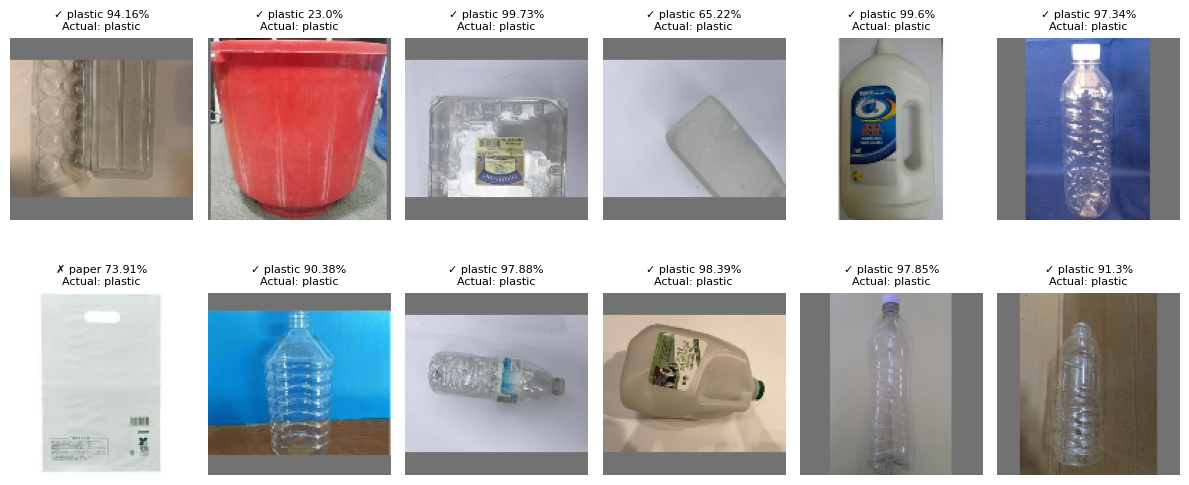

In [31]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import os
import math

model = tf.keras.models.load_model("/content/sortsnap_cnn_model.keras")

class_names = ['battery', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
IMG_SIZE = 256

# Change folder
folder_path = "/content/sortsnap_dataset/plastic"
actual_class = os.path.basename(folder_path)

# Number of images to show
num_images = 12

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_files = image_files[:num_images]

results = []

for img_name in image_files:
    img_path = os.path.join(folder_path, img_name)

    img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.efficientnet_v2.preprocess_input(img_array)

    predictions = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]
    confidence = predictions[0][predicted_index] * 100

    results.append({
        "image_name": img_name,
        "image_path": img_path,
        "actual": actual_class,
        "predicted": predicted_class,
        "confidence": round(float(confidence), 2),
        "correct": predicted_class == actual_class
    })

# Print text result
correct_count = sum(1 for r in results if r["correct"])

print("Prediction Results")
print("-" * 80)

for r in results:
    status = "CORRECT" if r["correct"] else "WRONG"
    print(
        f'{r["image_name"]} | Actual: {r["actual"]} | '
        f'Predicted: {r["predicted"]} | Confidence: {r["confidence"]}% | {status}'
    )

print("-" * 80)
print(f"Correct: {correct_count}/{len(results)}")
print(f"Accuracy for this batch: {round(correct_count / len(results) * 100, 2)}%")

# Smaller grid
cols = 6
rows = math.ceil(len(results) / cols)

plt.figure(figsize=(12, rows * 2.8))

for i, r in enumerate(results):
    img = image.load_img(r["image_path"], target_size=(128, 128))

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.axis("off")

    title_status = "✓" if r["correct"] else "✗"
    plt.title(
        f'{title_status} {r["predicted"]} {r["confidence"]}%\nActual: {r["actual"]}',
        fontsize=8
    )

plt.tight_layout()
plt.show()

Prediction Results
--------------------------------------------------------------------------------
paper_1333.jpg | Actual: paper | Predicted: paper | Confidence: 96.94% | CORRECT
paper_543.jpg | Actual: paper | Predicted: trash | Confidence: 48.82% | WRONG
paper_131.jpg | Actual: paper | Predicted: paper | Confidence: 95.37% | CORRECT
paper_969.jpg | Actual: paper | Predicted: paper | Confidence: 98.93% | CORRECT
paper_387.jpg | Actual: paper | Predicted: paper | Confidence: 99.42% | CORRECT
paper_1047.jpg | Actual: paper | Predicted: paper | Confidence: 92.74% | CORRECT
paper_327.jpg | Actual: paper | Predicted: paper | Confidence: 84.52% | CORRECT
paper_925.jpg | Actual: paper | Predicted: paper | Confidence: 50.65% | CORRECT
paper_912.jpg | Actual: paper | Predicted: paper | Confidence: 95.13% | CORRECT
paper_770.jpg | Actual: paper | Predicted: paper | Confidence: 63.09% | CORRECT
paper_328.jpg | Actual: paper | Predicted: paper | Confidence: 90.03% | CORRECT
paper_425.jpg | Actu

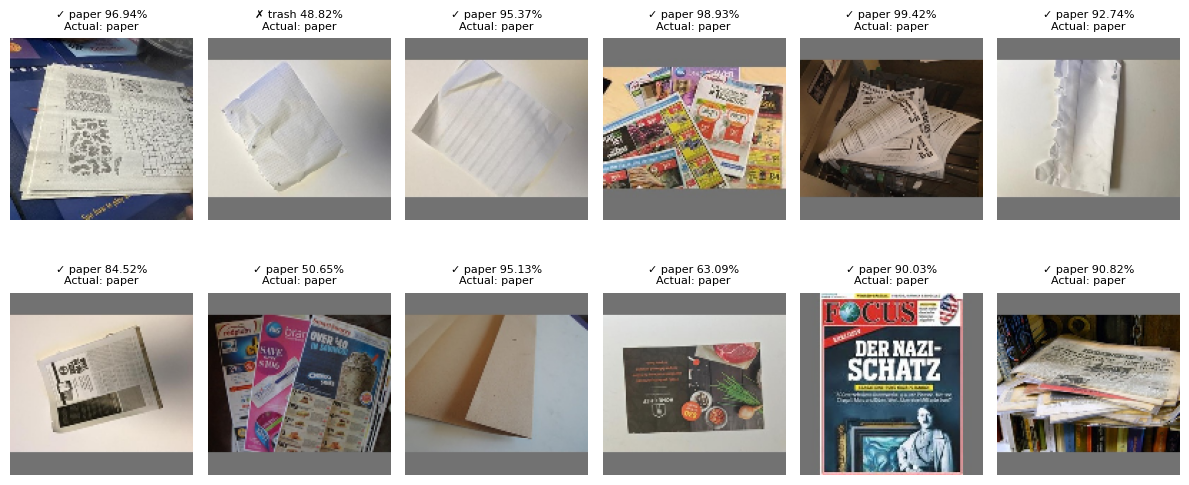

In [32]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import os
import math

model = tf.keras.models.load_model("/content/sortsnap_cnn_model.keras")

class_names = ['battery', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
IMG_SIZE = 256

# Change folder
folder_path = "/content/sortsnap_dataset/paper"
actual_class = os.path.basename(folder_path)

# Number of images to show
num_images = 12

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_files = image_files[:num_images]

results = []

for img_name in image_files:
    img_path = os.path.join(folder_path, img_name)

    img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.efficientnet_v2.preprocess_input(img_array)

    predictions = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]
    confidence = predictions[0][predicted_index] * 100

    results.append({
        "image_name": img_name,
        "image_path": img_path,
        "actual": actual_class,
        "predicted": predicted_class,
        "confidence": round(float(confidence), 2),
        "correct": predicted_class == actual_class
    })

# Print text result
correct_count = sum(1 for r in results if r["correct"])

print("Prediction Results")
print("-" * 80)

for r in results:
    status = "CORRECT" if r["correct"] else "WRONG"
    print(
        f'{r["image_name"]} | Actual: {r["actual"]} | '
        f'Predicted: {r["predicted"]} | Confidence: {r["confidence"]}% | {status}'
    )

print("-" * 80)
print(f"Correct: {correct_count}/{len(results)}")
print(f"Accuracy for this batch: {round(correct_count / len(results) * 100, 2)}%")

# Smaller grid
cols = 6
rows = math.ceil(len(results) / cols)

plt.figure(figsize=(12, rows * 2.8))

for i, r in enumerate(results):
    img = image.load_img(r["image_path"], target_size=(128, 128))

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.axis("off")

    title_status = "✓" if r["correct"] else "✗"
    plt.title(
        f'{title_status} {r["predicted"]} {r["confidence"]}%\nActual: {r["actual"]}',
        fontsize=8
    )

plt.tight_layout()
plt.show()

Prediction Results
--------------------------------------------------------------------------------
cardboard_1041.jpg | Actual: cardboard | Predicted: cardboard | Confidence: 98.87% | CORRECT
cardboard_1280.jpg | Actual: cardboard | Predicted: cardboard | Confidence: 95.85% | CORRECT
cardboard_550.jpg | Actual: cardboard | Predicted: cardboard | Confidence: 97.3% | CORRECT
cardboard_179.jpg | Actual: cardboard | Predicted: cardboard | Confidence: 45.86% | CORRECT
cardboard_788.jpg | Actual: cardboard | Predicted: cardboard | Confidence: 84.96% | CORRECT
cardboard_961.jpg | Actual: cardboard | Predicted: cardboard | Confidence: 86.16% | CORRECT
cardboard_39.jpg | Actual: cardboard | Predicted: cardboard | Confidence: 99.4% | CORRECT
cardboard_941.jpg | Actual: cardboard | Predicted: cardboard | Confidence: 98.2% | CORRECT
cardboard_484.jpg | Actual: cardboard | Predicted: metal | Confidence: 76.75% | WRONG
cardboard_841.jpg | Actual: cardboard | Predicted: cardboard | Confidence: 99.02

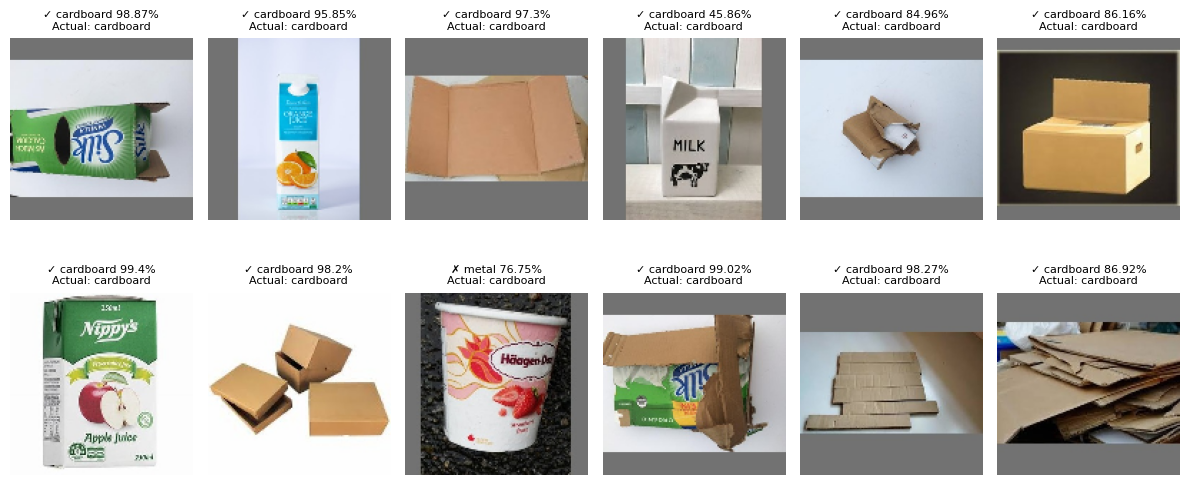

In [33]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import os
import math

model = tf.keras.models.load_model("/content/sortsnap_cnn_model.keras")

class_names = ['battery', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
IMG_SIZE = 256

# Change folder
folder_path = "/content/sortsnap_dataset/cardboard"
actual_class = os.path.basename(folder_path)

# Number of images to show
num_images = 12

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_files = image_files[:num_images]

results = []

for img_name in image_files:
    img_path = os.path.join(folder_path, img_name)

    img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.efficientnet_v2.preprocess_input(img_array)

    predictions = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]
    confidence = predictions[0][predicted_index] * 100

    results.append({
        "image_name": img_name,
        "image_path": img_path,
        "actual": actual_class,
        "predicted": predicted_class,
        "confidence": round(float(confidence), 2),
        "correct": predicted_class == actual_class
    })

# Print text result
correct_count = sum(1 for r in results if r["correct"])

print("Prediction Results")
print("-" * 80)

for r in results:
    status = "CORRECT" if r["correct"] else "WRONG"
    print(
        f'{r["image_name"]} | Actual: {r["actual"]} | '
        f'Predicted: {r["predicted"]} | Confidence: {r["confidence"]}% | {status}'
    )

print("-" * 80)
print(f"Correct: {correct_count}/{len(results)}")
print(f"Accuracy for this batch: {round(correct_count / len(results) * 100, 2)}%")

# Smaller grid
cols = 6
rows = math.ceil(len(results) / cols)

plt.figure(figsize=(12, rows * 2.8))

for i, r in enumerate(results):
    img = image.load_img(r["image_path"], target_size=(128, 128))

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.axis("off")

    title_status = "✓" if r["correct"] else "✗"
    plt.title(
        f'{title_status} {r["predicted"]} {r["confidence"]}%\nActual: {r["actual"]}',
        fontsize=8
    )

plt.tight_layout()
plt.show()

Prediction Results
--------------------------------------------------------------------------------
battery_728.jpg | Actual: battery | Predicted: battery | Confidence: 98.9% | CORRECT
battery_137.jpg | Actual: battery | Predicted: battery | Confidence: 99.82% | CORRECT
battery_156.jpg | Actual: battery | Predicted: battery | Confidence: 99.3% | CORRECT
battery_319.jpg | Actual: battery | Predicted: battery | Confidence: 99.81% | CORRECT
battery_464.jpg | Actual: battery | Predicted: battery | Confidence: 97.96% | CORRECT
battery_752.jpg | Actual: battery | Predicted: battery | Confidence: 97.33% | CORRECT
battery_291.jpg | Actual: battery | Predicted: battery | Confidence: 99.39% | CORRECT
battery_540.jpg | Actual: battery | Predicted: battery | Confidence: 99.68% | CORRECT
battery_63.jpg | Actual: battery | Predicted: cardboard | Confidence: 42.42% | WRONG
battery_422.jpg | Actual: battery | Predicted: battery | Confidence: 99.77% | CORRECT
battery_87.jpg | Actual: battery | Predicte

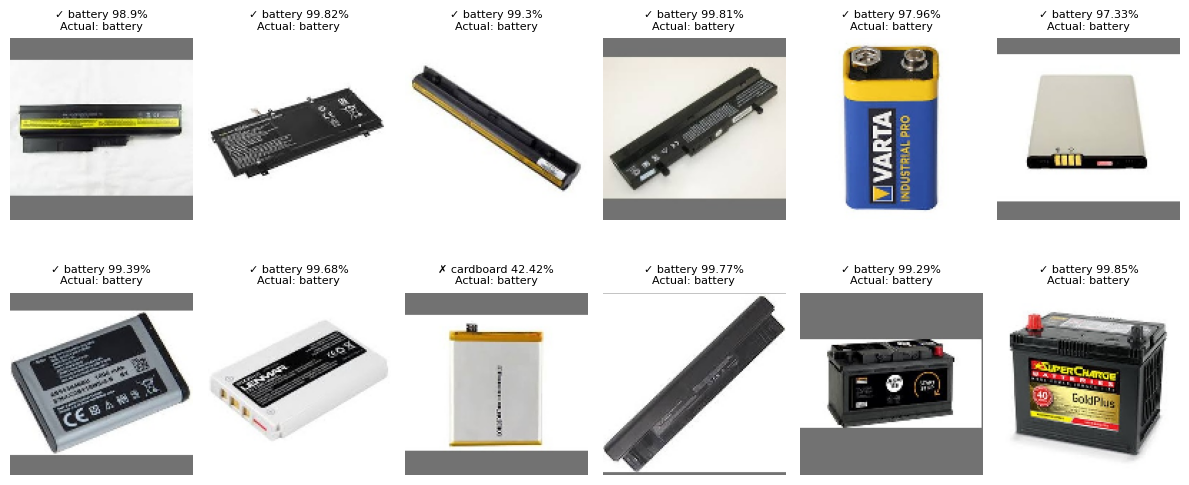

In [34]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import os
import math

model = tf.keras.models.load_model("/content/sortsnap_cnn_model.keras")

class_names = ['battery', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
IMG_SIZE = 256

# Change folder
folder_path = "/content/sortsnap_dataset/battery"
actual_class = os.path.basename(folder_path)

# Number of images to show
num_images = 12

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_files = image_files[:num_images]

results = []

for img_name in image_files:
    img_path = os.path.join(folder_path, img_name)

    img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.efficientnet_v2.preprocess_input(img_array)

    predictions = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]
    confidence = predictions[0][predicted_index] * 100

    results.append({
        "image_name": img_name,
        "image_path": img_path,
        "actual": actual_class,
        "predicted": predicted_class,
        "confidence": round(float(confidence), 2),
        "correct": predicted_class == actual_class
    })

# Print text result
correct_count = sum(1 for r in results if r["correct"])

print("Prediction Results")
print("-" * 80)

for r in results:
    status = "CORRECT" if r["correct"] else "WRONG"
    print(
        f'{r["image_name"]} | Actual: {r["actual"]} | '
        f'Predicted: {r["predicted"]} | Confidence: {r["confidence"]}% | {status}'
    )

print("-" * 80)
print(f"Correct: {correct_count}/{len(results)}")
print(f"Accuracy for this batch: {round(correct_count / len(results) * 100, 2)}%")

# Smaller grid
cols = 6
rows = math.ceil(len(results) / cols)

plt.figure(figsize=(12, rows * 2.8))

for i, r in enumerate(results):
    img = image.load_img(r["image_path"], target_size=(128, 128))

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.axis("off")

    title_status = "✓" if r["correct"] else "✗"
    plt.title(
        f'{title_status} {r["predicted"]} {r["confidence"]}%\nActual: {r["actual"]}',
        fontsize=8
    )

plt.tight_layout()
plt.show()

Prediction Results
--------------------------------------------------------------------------------
glass_1251.jpg | Actual: glass | Predicted: glass | Confidence: 58.78% | CORRECT
glass_400.jpg | Actual: glass | Predicted: glass | Confidence: 99.69% | CORRECT
glass_1277.jpg | Actual: glass | Predicted: glass | Confidence: 94.82% | CORRECT
glass_1285.jpg | Actual: glass | Predicted: glass | Confidence: 94.39% | CORRECT
glass_201.jpg | Actual: glass | Predicted: glass | Confidence: 99.0% | CORRECT
glass_52.jpg | Actual: glass | Predicted: glass | Confidence: 54.37% | CORRECT
glass_503.jpg | Actual: glass | Predicted: glass | Confidence: 91.21% | CORRECT
glass_1124.jpg | Actual: glass | Predicted: glass | Confidence: 99.58% | CORRECT
glass_751.jpg | Actual: glass | Predicted: glass | Confidence: 98.97% | CORRECT
glass_1260.jpg | Actual: glass | Predicted: glass | Confidence: 99.3% | CORRECT
glass_1286.jpg | Actual: glass | Predicted: glass | Confidence: 97.25% | CORRECT
glass_773.jpg | A

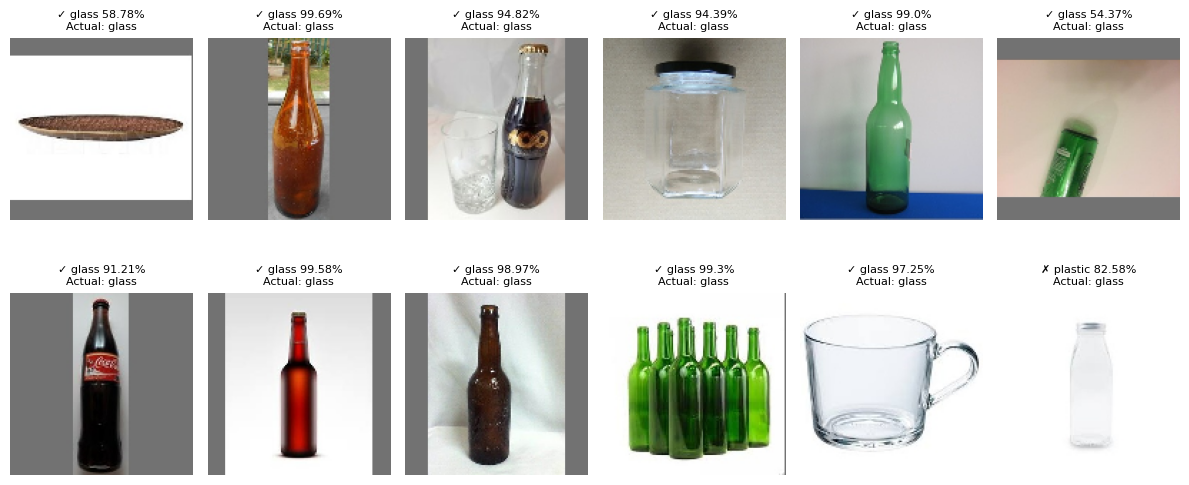

In [35]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import os
import math

model = tf.keras.models.load_model("/content/sortsnap_cnn_model.keras")

class_names = ['battery', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
IMG_SIZE = 256

# Change folder
folder_path = "/content/sortsnap_dataset/glass"
actual_class = os.path.basename(folder_path)

# Number of images to show
num_images = 12

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_files = image_files[:num_images]

results = []

for img_name in image_files:
    img_path = os.path.join(folder_path, img_name)

    img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.efficientnet_v2.preprocess_input(img_array)

    predictions = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]
    confidence = predictions[0][predicted_index] * 100

    results.append({
        "image_name": img_name,
        "image_path": img_path,
        "actual": actual_class,
        "predicted": predicted_class,
        "confidence": round(float(confidence), 2),
        "correct": predicted_class == actual_class
    })

# Print text result
correct_count = sum(1 for r in results if r["correct"])

print("Prediction Results")
print("-" * 80)

for r in results:
    status = "CORRECT" if r["correct"] else "WRONG"
    print(
        f'{r["image_name"]} | Actual: {r["actual"]} | '
        f'Predicted: {r["predicted"]} | Confidence: {r["confidence"]}% | {status}'
    )

print("-" * 80)
print(f"Correct: {correct_count}/{len(results)}")
print(f"Accuracy for this batch: {round(correct_count / len(results) * 100, 2)}%")

# Smaller grid
cols = 6
rows = math.ceil(len(results) / cols)

plt.figure(figsize=(12, rows * 2.8))

for i, r in enumerate(results):
    img = image.load_img(r["image_path"], target_size=(128, 128))

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.axis("off")

    title_status = "✓" if r["correct"] else "✗"
    plt.title(
        f'{title_status} {r["predicted"]} {r["confidence"]}%\nActual: {r["actual"]}',
        fontsize=8
    )

plt.tight_layout()
plt.show()

Prediction Results
--------------------------------------------------------------------------------
metal_284.jpg | Actual: metal | Predicted: metal | Confidence: 99.49% | CORRECT
metal_318.jpg | Actual: metal | Predicted: metal | Confidence: 95.16% | CORRECT
metal_531.jpg | Actual: metal | Predicted: metal | Confidence: 98.92% | CORRECT
metal_124.jpg | Actual: metal | Predicted: metal | Confidence: 52.43% | CORRECT
metal_854.jpg | Actual: metal | Predicted: metal | Confidence: 94.43% | CORRECT
metal_570.jpg | Actual: metal | Predicted: glass | Confidence: 55.51% | WRONG
metal_214.jpg | Actual: metal | Predicted: metal | Confidence: 99.0% | CORRECT
metal_274.jpg | Actual: metal | Predicted: metal | Confidence: 97.73% | CORRECT
metal_119.jpg | Actual: metal | Predicted: metal | Confidence: 97.2% | CORRECT
metal_152.jpg | Actual: metal | Predicted: metal | Confidence: 99.53% | CORRECT
metal_544.jpg | Actual: metal | Predicted: metal | Confidence: 77.96% | CORRECT
metal_893.jpg | Actual: 

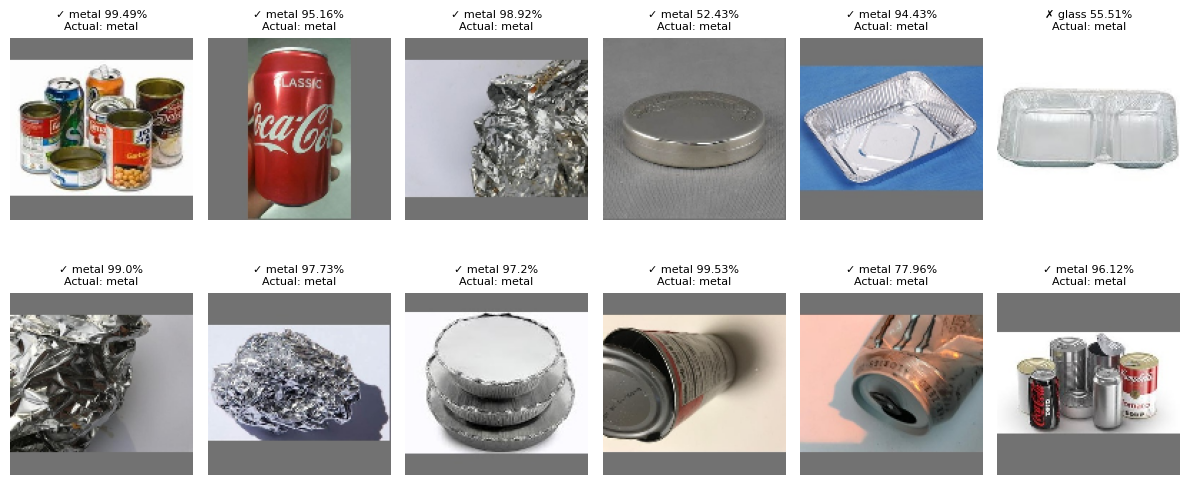

In [36]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import os
import math

model = tf.keras.models.load_model("/content/sortsnap_cnn_model.keras")

class_names = ['battery', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
IMG_SIZE = 256

# Change folder
folder_path = "/content/sortsnap_dataset/metal"
actual_class = os.path.basename(folder_path)

# Number of images to show
num_images = 12

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_files = image_files[:num_images]

results = []

for img_name in image_files:
    img_path = os.path.join(folder_path, img_name)

    img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.efficientnet_v2.preprocess_input(img_array)

    predictions = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]
    confidence = predictions[0][predicted_index] * 100

    results.append({
        "image_name": img_name,
        "image_path": img_path,
        "actual": actual_class,
        "predicted": predicted_class,
        "confidence": round(float(confidence), 2),
        "correct": predicted_class == actual_class
    })

# Print text result
correct_count = sum(1 for r in results if r["correct"])

print("Prediction Results")
print("-" * 80)

for r in results:
    status = "CORRECT" if r["correct"] else "WRONG"
    print(
        f'{r["image_name"]} | Actual: {r["actual"]} | '
        f'Predicted: {r["predicted"]} | Confidence: {r["confidence"]}% | {status}'
    )

print("-" * 80)
print(f"Correct: {correct_count}/{len(results)}")
print(f"Accuracy for this batch: {round(correct_count / len(results) * 100, 2)}%")

# Smaller grid
cols = 6
rows = math.ceil(len(results) / cols)

plt.figure(figsize=(12, rows * 2.8))

for i, r in enumerate(results):
    img = image.load_img(r["image_path"], target_size=(128, 128))

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.axis("off")

    title_status = "✓" if r["correct"] else "✗"
    plt.title(
        f'{title_status} {r["predicted"]} {r["confidence"]}%\nActual: {r["actual"]}',
        fontsize=8
    )

plt.tight_layout()
plt.show()

Prediction Results
--------------------------------------------------------------------------------
trash_74.jpg | Actual: trash | Predicted: glass | Confidence: 87.32% | WRONG
trash_134.jpg | Actual: trash | Predicted: trash | Confidence: 96.81% | CORRECT
trash_238.jpg | Actual: trash | Predicted: metal | Confidence: 91.36% | WRONG
trash_453.jpg | Actual: trash | Predicted: paper | Confidence: 60.75% | WRONG
trash_75.jpg | Actual: trash | Predicted: trash | Confidence: 82.36% | CORRECT
trash_409.jpg | Actual: trash | Predicted: trash | Confidence: 97.15% | CORRECT
trash_46.jpg | Actual: trash | Predicted: trash | Confidence: 44.31% | CORRECT
trash_103.jpg | Actual: trash | Predicted: trash | Confidence: 30.29% | CORRECT
trash_431.jpg | Actual: trash | Predicted: trash | Confidence: 84.76% | CORRECT
trash_377.jpg | Actual: trash | Predicted: trash | Confidence: 56.39% | CORRECT
trash_335.jpg | Actual: trash | Predicted: trash | Confidence: 98.65% | CORRECT
trash_128.jpg | Actual: trash

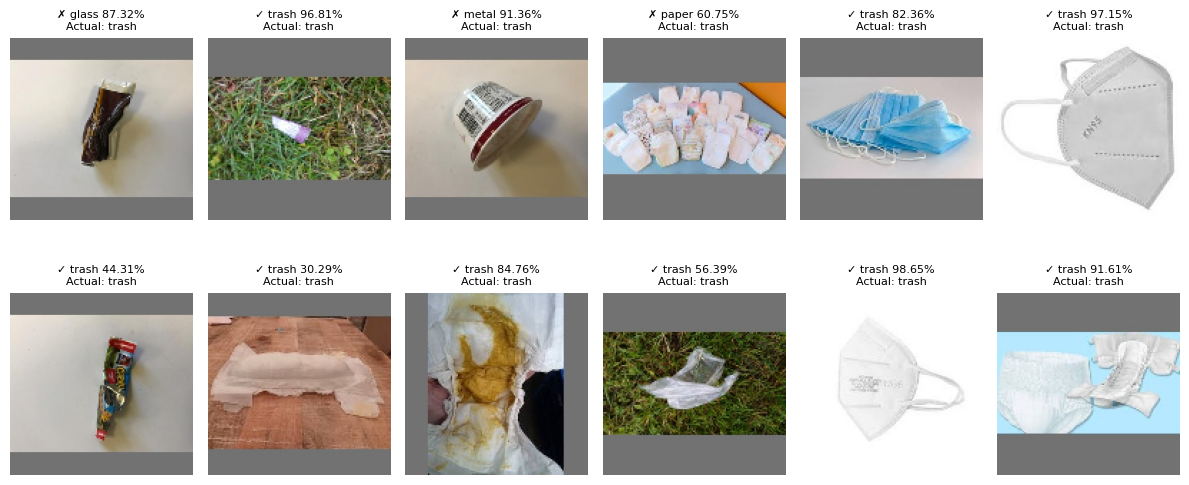

In [37]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import os
import math

model = tf.keras.models.load_model("/content/sortsnap_cnn_model.keras")

class_names = ['battery', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
IMG_SIZE = 256

# Change folder
folder_path = "/content/sortsnap_dataset/trash"
actual_class = os.path.basename(folder_path)

# Number of images to show
num_images = 12

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_files = image_files[:num_images]

results = []

for img_name in image_files:
    img_path = os.path.join(folder_path, img_name)

    img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.efficientnet_v2.preprocess_input(img_array)

    predictions = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]
    confidence = predictions[0][predicted_index] * 100

    results.append({
        "image_name": img_name,
        "image_path": img_path,
        "actual": actual_class,
        "predicted": predicted_class,
        "confidence": round(float(confidence), 2),
        "correct": predicted_class == actual_class
    })

# Print text result
correct_count = sum(1 for r in results if r["correct"])

print("Prediction Results")
print("-" * 80)

for r in results:
    status = "CORRECT" if r["correct"] else "WRONG"
    print(
        f'{r["image_name"]} | Actual: {r["actual"]} | '
        f'Predicted: {r["predicted"]} | Confidence: {r["confidence"]}% | {status}'
    )

print("-" * 80)
print(f"Correct: {correct_count}/{len(results)}")
print(f"Accuracy for this batch: {round(correct_count / len(results) * 100, 2)}%")

# Smaller grid
cols = 6
rows = math.ceil(len(results) / cols)

plt.figure(figsize=(12, rows * 2.8))

for i, r in enumerate(results):
    img = image.load_img(r["image_path"], target_size=(128, 128))

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.axis("off")

    title_status = "✓" if r["correct"] else "✗"
    plt.title(
        f'{title_status} {r["predicted"]} {r["confidence"]}%\nActual: {r["actual"]}',
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [38]:
model.save("/content/sortsnap_cnn_model.keras")

print("Final model saved as sortsnap_cnn_model.keras")

Final model saved as sortsnap_cnn_model.keras
